#**Analisis Aspek dan Sentimen Review Pengguna Aplikasi Shopee di Play Store Menggunakan Topic Modeling LDA dan Naive Bayes**

# **Anggota Kelompok 6**

1.   Nadine Putri Aulia (24031554094)
2.   Putri Sofiyatus Salwa (24031554112)
3.   Arya Abdi Wicaksana		(24031554224)


#**Scrapping Data Dari Google Play Store**

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install google-play-scraper pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.6 MB/s eta 0:00:00


In [ ]:
from google_play_scraper import Sort, reviews
import pandas as pd

package_name = 'com.shopee.id'

result, _ = reviews(
    package_name,
    lang='id',
    country='id',
    sort=Sort.NEWEST,
    count=1000
)

data = []
for r in result:
    data.append({
        'userName': r['userName'],
        'review': r['content'],
        'score': r['score'],
        'at': r['at']
    })

df = pd.DataFrame(data)

df.to_csv('shopee_reviews.csv', index=False, encoding='utf-8-sig')
print(f"Total review berhasil diambil: {len(df)}")

Total review berhasil diambil: 1000


#**Label Sentiment Berdasarkan Rating**

In [ ]:
df = pd.read_csv('/content/drive/Shareddrives/Project_pemteks_kel.6/shopee_reviews_fix(1).csv')
df = df[['userName', 'review', 'score']]
df.head()

,userName,review,score
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3
1,Boru Lubis,i love shopee,5
2,Ismail Falisha,Sangat membantu,4
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3
4,Thisya Kavindra,"gatau, suka aja",5


In [ ]:
def get_sentiment(score):
    if score >= 4:
        return "positif"
    elif score == 3:
        return "netral"
    else:
        return "negatif"

df["sentiment"] = df["score"].apply(get_sentiment)
df.head()

,userName,review,score,sentiment
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral
1,Boru Lubis,i love shopee,5,positif
2,Ismail Falisha,Sangat membantu,4,positif
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral
4,Thisya Kavindra,"gatau, suka aja",5,positif


#**Pre-Processing**

In [ ]:
!pip install emoji
!pip install Sastrawi

import pandas as pd
import re
import nltk
import string
from nltk.tokenize import word_tokenize
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 4.4 MB/s eta 0:00:00


In [ ]:
nltk.download('punkt')

df = df[['userName', 'review', 'score', 'sentiment']]
df.head()

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


,userName,review,score,sentiment
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral
1,Boru Lubis,i love shopee,5,positif
2,Ismail Falisha,Sangat membantu,4,positif
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral
4,Thisya Kavindra,"gatau, suka aja",5,positif


In [ ]:
#lowercasing
df['review_clean'] = df['review'].str.lower()
df.head()

,userName,review,score,sentiment,review_clean
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus karena layanan cod tidak bisa
1,Boru Lubis,i love shopee,5,positif,i love shopee
2,Ismail Falisha,Sangat membantu,4,positif,sangat membantu
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,sebulan ini klo masih di beku kan auto uninstall
4,Thisya Kavindra,"gatau, suka aja",5,positif,"gatau, suka aja"


In [ ]:
#menghapus angka
df['review_clean'] = df['review_clean'].str.replace(r'[^a-zA-Z\s]', ' ', regex=True)
df.head()

,userName,review,score,sentiment,review_clean
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus karena layanan cod tidak bisa
1,Boru Lubis,i love shopee,5,positif,i love shopee
2,Ismail Falisha,Sangat membantu,4,positif,sangat membantu
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,sebulan ini klo masih di beku kan auto uninstall
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja


In [ ]:
#remove emoji
def remove_emoji(text):
    emoji_pattern = re.compile(
        "["
        u"\U0001F600-\U0001F64F"
        u"\U0001F300-\U0001F5FF"
        u"\U0001F680-\U0001F6FF"
        u"\U0001F1E0-\U0001F1FF"
        u"\U00002702-\U000027B0"
        u"\U000024C2-\U0001F251"
        "]+",
        flags=re.UNICODE
    )
    return emoji_pattern.sub(r'', text)

df["review_clean"] = df["review_clean"].astype(str).apply(remove_emoji)
df.head()

,userName,review,score,sentiment,review_clean
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus karena layanan cod tidak bisa
1,Boru Lubis,i love shopee,5,positif,i love shopee
2,Ismail Falisha,Sangat membantu,4,positif,sangat membantu
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,sebulan ini klo masih di beku kan auto uninstall
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja


In [ ]:
#removepunctuation
def remove_punct(text):
    return re.sub(f"[{re.escape(string.punctuation)}]", " ", text)

df["review_clean"] = df["review_clean"].apply(remove_punct)
df.head()

,userName,review,score,sentiment,review_clean
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus karena layanan cod tidak bisa
1,Boru Lubis,i love shopee,5,positif,i love shopee
2,Ismail Falisha,Sangat membantu,4,positif,sangat membantu
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,sebulan ini klo masih di beku kan auto uninstall
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja


In [ ]:
#slangword
nltk.download('punkt')
nltk.download('punkt_tab')

slang_df = pd.read_excel("/content/drive/Shareddrives/Project_pemteks_kel.6/slang_word_fix.xlsx")

slang_dict = dict(zip(slang_df["slang"], slang_df["normal"]))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
def normalize_slang(text):
    if pd.isna(text):
        return ""
    tokens = word_tokenize(text.lower())
    new_tokens = []

    for token in tokens:
        if token in slang_dict:
            new_tokens.append(slang_dict[token])
        else:
            new_tokens.append(token)

    return " ".join(new_tokens)

df["review_clean"] = df["review_clean"].apply(normalize_slang)
df.head()

,userName,review,score,sentiment,review_clean
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus karena layanan cod tidak bisa
1,Boru Lubis,i love shopee,5,positif,i love shopee
2,Ismail Falisha,Sangat membantu,4,positif,sangat membantu
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,satu bulan ini kalau masih di beku kan auto un...
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja


In [ ]:
#remove stopwords
with open("/content/drive/Shareddrives/Project_pemteks_kel.6/stopwords(1).txt", "r", encoding="utf-8") as f:
    custom_stopwords = set([line.strip() for line in f])

def remove_stopwords(text):
    return " ".join([word for word in text.split() if word not in custom_stopwords])

df["review_clean"] = df["review_clean"].apply(remove_stopwords)
df.head()

,userName,review,score,sentiment,review_clean
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus layanan cod tidak
1,Boru Lubis,i love shopee,5,positif,i love shopee
2,Ismail Falisha,Sangat membantu,4,positif,membantu
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,satu bulan beku auto uninstall
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja


In [ ]:
#stemming
factory = StemmerFactory()
stemmer = factory.create_stemmer()

df["review_clean"] = df["review_clean"].apply(lambda x: " ".join([stemmer.stem(w) for w in x.split()]))
df.head()

,userName,review,score,sentiment,review_clean
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus layan cod tidak
1,Boru Lubis,i love shopee,5,positif,i love shopee
2,Ismail Falisha,Sangat membantu,4,positif,bantu
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,satu bulan beku auto uninstall
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja


In [ ]:
df = df[df['review_clean'].map(lambda x: len(x) != 0)].reset_index(drop=True)

In [ ]:
#Tokenisasi(ubah kalimat menjadi list kata)
df['tokens'] = df['review_clean'].apply(lambda x: x.split())
df.head()

,userName,review,score,sentiment,review_clean,tokens
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus layan cod tidak,"[kurang, bagus, layan, cod, tidak]"
1,Boru Lubis,i love shopee,5,positif,i love shopee,"[i, love, shopee]"
2,Ismail Falisha,Sangat membantu,4,positif,bantu,[bantu]
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,satu bulan beku auto uninstall,"[satu, bulan, beku, auto, uninstall]"
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja,"[gatau, suka, aja]"


In [ ]:
df.to_csv('/content/drive/Shareddrives/Project_pemteks_kel.6/shopee_reviews_pre-processing.csv', index=False, encoding='utf-8-sig')

#**EDA - Setelah Preprocessing**

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud

df.head()

,userName,review,score,sentiment,review_clean,tokens
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus layan cod tidak,"[kurang, bagus, layan, cod, tidak]"
1,Boru Lubis,i love shopee,5,positif,i love shopee,"[i, love, shopee]"
2,Ismail Falisha,Sangat membantu,4,positif,bantu,[bantu]
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,satu bulan beku auto uninstall,"[satu, bulan, beku, auto, uninstall]"
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja,"[gatau, suka, aja]"


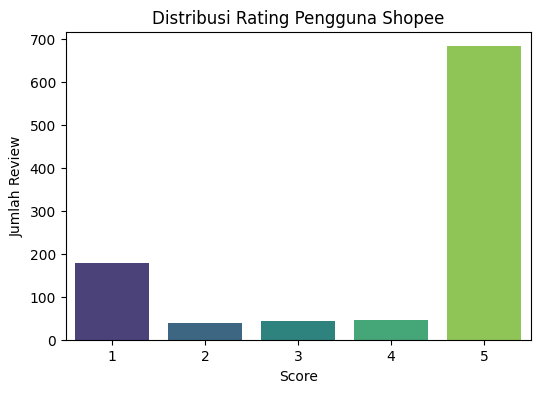

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="score", palette="viridis")
plt.title("Distribusi Rating Pengguna Shopee")
plt.xlabel("Score")
plt.ylabel("Jumlah Review")
plt.show()

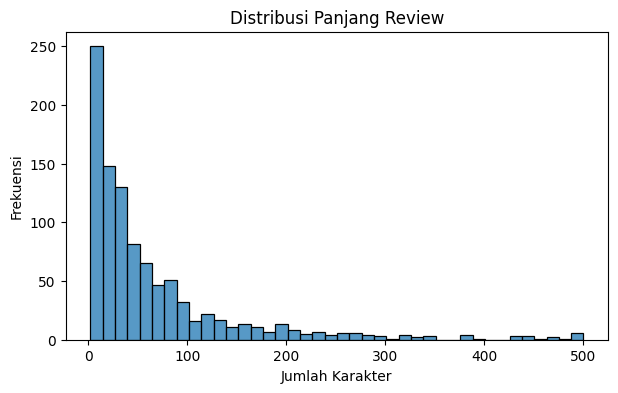

In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(df["review"].astype(str).apply(len), bins=40)
plt.title("Distribusi Panjang Review")
plt.xlabel("Jumlah Karakter")
plt.ylabel("Frekuensi")
plt.show()

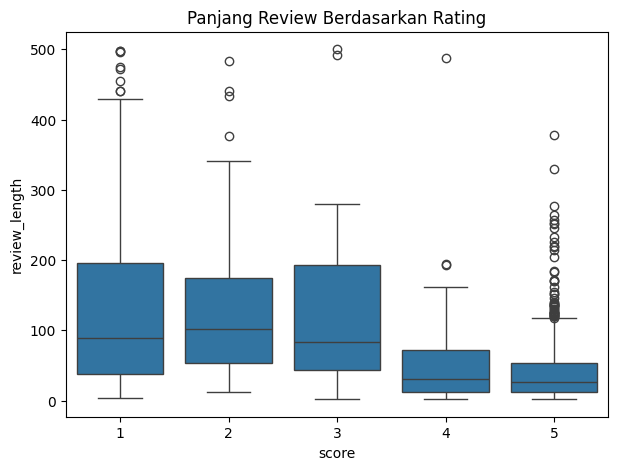

In [ ]:
plt.figure(figsize=(7,5))
sns.boxplot(x=df["score"], y=df["review"].astype(str).apply(len))
plt.title("Panjang Review Berdasarkan Rating")
plt.xlabel("score")
plt.ylabel("review_length")
plt.show()

In [ ]:
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")
from collections import Counter
nltk.download("punkt")

all_words = []
for text in df["review"].astype(str):
    all_words += nltk.word_tokenize(text.lower())

word_freq = Counter(all_words).most_common(20)
word_freq

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


[(',', 427),
 ('di', 275),
 ('shopee', 244),
 ('.', 220),
 ('dan', 194),
 ('sangat', 191),
 ('saya', 147),
 ('bagus', 139),
 ('belanja', 138),
 ('nya', 126),
 ('barang', 116),
 ('pengiriman', 103),
 ('bisa', 100),
 ('yg', 97),
 ('aplikasi', 96),
 ('ada', 95),
 ('tidak', 92),
 ('yang', 92),
 ('ini', 83),
 ('..', 73)]

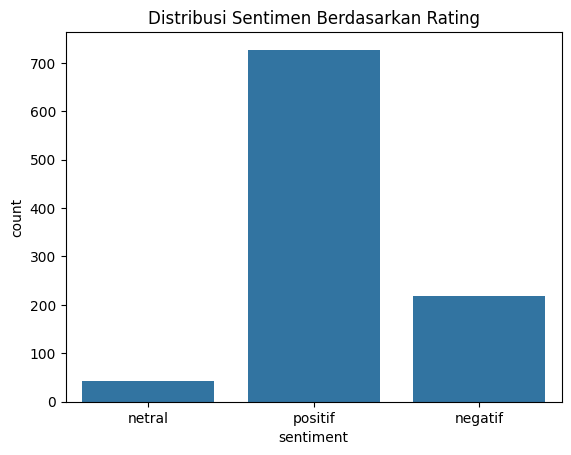

In [ ]:
sns.countplot(data=df, x="sentiment")
plt.title("Distribusi Sentimen Berdasarkan Rating")
plt.show()

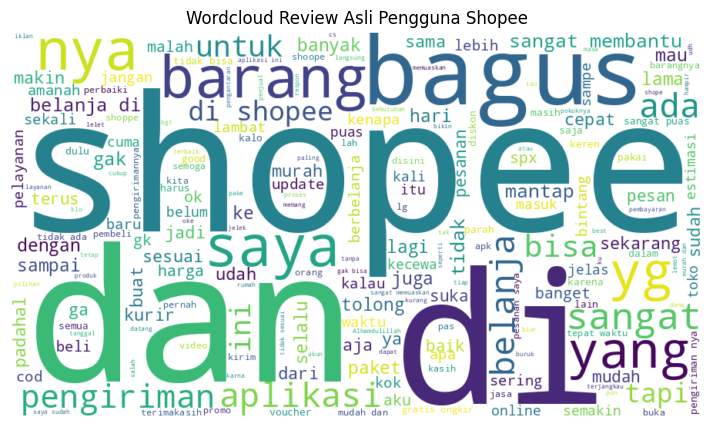

In [ ]:
text = " ".join(df["review"].astype(str))

wc = WordCloud(width=900, height=500, background_color="white").generate(text)

plt.figure(figsize=(10,5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Wordcloud Review Asli Pengguna Shopee")
plt.show()

#**Pelatihan Model Naive Bayes**

In [ ]:
#TF-IDF Vectorizer untuk Naive Bayes
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df["review_clean"])
y = df["sentiment"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
     X, y, test_size=0.3, random_state=42, stratify=y
 )

## **Penanganan Imbalance Data (SMOTE)**

In [ ]:
#SMOTE
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

## **Evaluasi Model Klasifikasi Naive Bayes**

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

In [ ]:
#Tanpa SMOTE
nb_before = MultinomialNB()
nb_before.fit(X_train, y_train)

y_pred_before = nb_before.predict(X_test)

print("Akurasi:", accuracy_score(y_test, y_pred_before))
print(classification_report(y_test, y_pred_before))

Akurasi: 0.8316498316498316
              precision    recall  f1-score   support

     negatif       0.88      0.45      0.60        66
      netral       0.00      0.00      0.00        13
     positif       0.83      1.00      0.90       218

    accuracy                           0.83       297
   macro avg       0.57      0.48      0.50       297
weighted avg       0.80      0.83      0.80       297



In [ ]:
#Menggunakan SMOTE
nb_after = MultinomialNB()
nb_after.fit(X_train_smote, y_train_smote)

y_pred_after = nb_after.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred_after))
print(classification_report(y_test, y_pred_after))

Akurasi: 0.8013468013468014
              precision    recall  f1-score   support

     negatif       0.64      0.70      0.67        66
      netral       0.08      0.15      0.11        13
     positif       0.95      0.87      0.91       218

    accuracy                           0.80       297
   macro avg       0.56      0.57      0.56       297
weighted avg       0.84      0.80      0.82       297



## **Confusion Matrix NB + SMOTE**

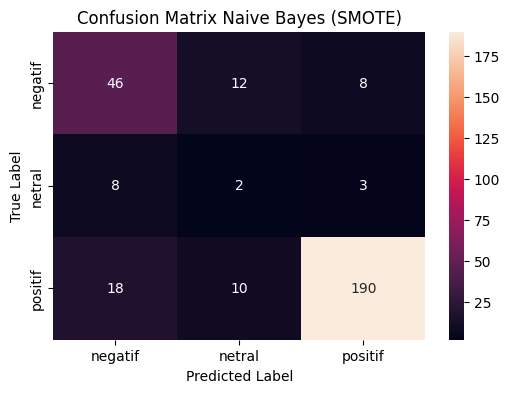

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Confusion Matrix NB + SMOTE
cm_nb_after = confusion_matrix(
    y_test,
    y_pred_after,
    labels=["negatif", "netral", "positif"]
)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm_nb_after,
    annot=True,
    fmt="d",
    xticklabels=["negatif", "netral", "positif"],
    yticklabels=["negatif", "netral", "positif"]
)
plt.title("Confusion Matrix Naive Bayes (SMOTE)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
# Buat kolom sentimen hasil prediksi NB
df["NB_sentiment"] = nb_after.predict(X)
df.to_csv("/content/drive/Shareddrives/Project_pemteks_kel.6/NB_sentiment.csv", index=False)
df.head()

,userName,review,score,sentiment,review_clean,tokens,NB_sentiment
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus layan cod tidak,"[kurang, bagus, layan, cod, tidak]",netral
1,Boru Lubis,i love shopee,5,positif,i love shopee,"[i, love, shopee]",positif
2,Ismail Falisha,Sangat membantu,4,positif,bantu,[bantu],positif
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,satu bulan beku auto uninstall,"[satu, bulan, beku, auto, uninstall]",netral
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja,"[gatau, suka, aja]",positif


##**Percobaan menggunakan SVM**

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [ ]:
#Tanpa class weight
svm_before = SVC(kernel="linear")
svm_before.fit(X_train, y_train)

y_pred_before = svm_before.predict(X_test)

print("Akurasi:", accuracy_score(y_test, y_pred_before))
print(classification_report(y_test, y_pred_before))

Akurasi: 0.8787878787878788
              precision    recall  f1-score   support

     negatif       0.77      0.80      0.79        66
      netral       0.00      0.00      0.00        13
     positif       0.91      0.95      0.93       218

    accuracy                           0.88       297
   macro avg       0.56      0.59      0.57       297
weighted avg       0.84      0.88      0.86       297



In [ ]:
#menggunakan class weight
model = SVC(kernel="linear", class_weight="balanced")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Akurasi: 0.835016835016835
              precision    recall  f1-score   support

     negatif       0.63      0.83      0.72        66
      netral       0.00      0.00      0.00        13
     positif       0.95      0.89      0.91       218

    accuracy                           0.84       297
   macro avg       0.53      0.57      0.54       297
weighted avg       0.83      0.84      0.83       297



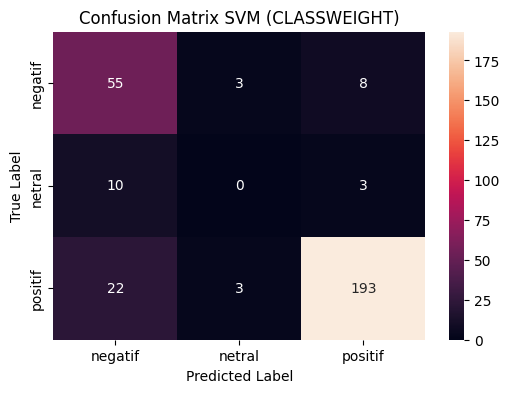

In [ ]:
# Confusion Matrix SVM + CLASSWEIGHT
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negatif", "netral", "positif"]
)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["negatif", "netral", "positif"],
    yticklabels=["negatif", "netral", "positif"]
)
plt.title("Confusion Matrix SVM (CLASSWEIGHT)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
# # Buat kolom sentimen hasil prediksi SVM
# df["svm_sentiment"] = model.predict(X)
# df.to_csv("/content/drive/Shareddrives/Project_pemteks_kel.6/svm_sentiment.csv", index=False)
# df.head()

#**Topic Modelling (LDA)**

## **Count Vectorizer (BoW)**

In [ ]:
#Countvectorizer (BOW) untuk LDA
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['review_clean'])

## **Coherence**

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 72.9 MB/s eta 0:00:00


In [ ]:
from gensim.models import LdaModel
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#COHERENCE
texts = df['tokens']

dictionary = Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]

coherence_scores = []
topic_range = range(2, 11)

for num_topics in topic_range:
    lda_model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=num_topics, passes=10, random_state=42)
    coherence_model = CoherenceModel(model=lda_model, texts=texts, dictionary=dictionary, coherence='c_v')
    score = coherence_model.get_coherence()
    coherence_scores.append(score)
    print(f"Topik {num_topics}: Coherence Score = {score}")

Topik 2: Coherence Score = 0.49881496483485677
Topik 3: Coherence Score = 0.47748130973978536
Topik 4: Coherence Score = 0.4711003254037358
Topik 5: Coherence Score = 0.508401295510456
Topik 6: Coherence Score = 0.48339199991024717
Topik 7: Coherence Score = 0.4487469751530466
Topik 8: Coherence Score = 0.44314874684571154
Topik 9: Coherence Score = 0.44956541985476783
Topik 10: Coherence Score = 0.4342282072913772


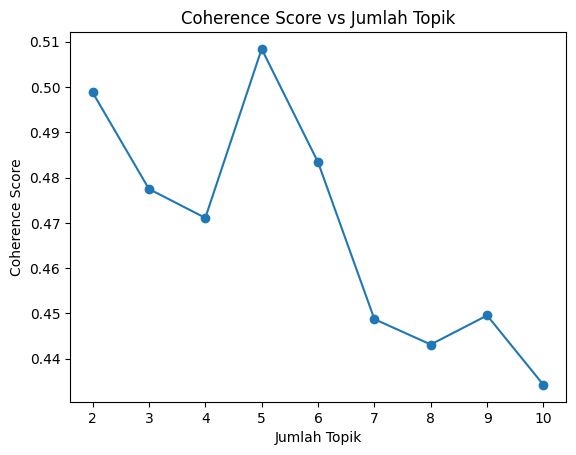

In [ ]:
plt.plot(topic_range, coherence_scores, marker='o')
plt.title("Coherence Score vs Jumlah Topik")
plt.xlabel("Jumlah Topik")
plt.ylabel("Coherence Score")
plt.xticks(topic_range)
plt.show()

## **LDA - Positif**

In [ ]:
df_pos_NB = df[df["NB_sentiment"] == "positif"]
df_neg_NB = df[df["NB_sentiment"] == "negatif"]
df_neu_NB = df[df["NB_sentiment"] == "netral"]

In [ ]:
texts = df_pos_NB["tokens"]

dictionary_pos_NB = Dictionary(texts)
corpus_pos_NB = [dictionary_pos_NB.doc2bow(text) for text in texts]

lda_pos_NB = LdaModel(
    corpus=corpus_pos_NB,
    id2word=dictionary_pos_NB,
    num_topics=5,
    passes=15,
    random_state=42
)

def topics_positif(lda_model, num_words=10):
    for topic_id in range(lda_model.num_topics):
        print(f"\nTopik {topic_id}:")
        terms = lda_model.show_topic(topic_id, num_words)
        for word, weight in terms:
            print(f" - {word} ({weight:.3f})")

print("TOPIK SENTIMEN NB POSITIF")
topics_positif(lda_pos_NB)

TOPIK SENTIMEN NB POSITIF

Topik 0:
 - oke (0.115)
 - keren (0.053)
 - tidak (0.016)
 - barang (0.016)
 - shopee (0.016)
 - pokok (0.015)
 - poko (0.014)
 - mantap (0.012)
 - betul (0.012)
 - very (0.009)

Topik 1:
 - belanja (0.089)
 - bagus (0.088)
 - shopee (0.062)
 - mudah (0.053)
 - bantu (0.045)
 - murah (0.035)
 - barang (0.035)
 - untuk (0.025)
 - aplikasi (0.023)
 - cepat (0.020)

Topik 2:
 - mantap (0.161)
 - shopee (0.041)
 - amanah (0.037)
 - aplikasi (0.028)
 - produk (0.027)
 - toko (0.021)
 - tidak (0.015)
 - jadi (0.015)
 - terima (0.015)
 - kasih (0.012)

Topik 3:
 - shopee (0.085)
 - baik (0.041)
 - belanja (0.035)
 - kasih (0.029)
 - ongkir (0.025)
 - terima (0.023)
 - tidak (0.020)
 - banget (0.017)
 - aplikasi (0.017)
 - suka (0.016)

Topik 4:
 - muas (0.058)
 - good (0.040)
 - puas (0.037)
 - beri (0.019)
 - kirim (0.018)
 - barang (0.016)
 - kak (0.016)
 - cepat (0.014)
 - shopee (0.014)
 - waktu (0.014)


## **LDA - Netral**

In [ ]:
texts = df_neu_NB["tokens"]

dictionary_neu_NB = Dictionary(texts)
corpus_neu_NB = [dictionary_neu_NB.doc2bow(text) for text in texts]

lda_neu_NB = LdaModel(
    corpus=corpus_neu_NB,
    id2word=dictionary_neu_NB,
    num_topics=5,
    passes=15,
    random_state=42
)

def topics_netral(lda_model, num_words=10):
    for topic_id in range(lda_model.num_topics):
        print(f"\nTopik {topic_id}:")
        terms = lda_model.show_topic(topic_id, num_words)
        for word, weight in terms:
            print(f" - {word} ({weight:.3f})")

print("TOPIK SENTIMEN NB NETRAL")
topics_netral(lda_neu_NB)

TOPIK SENTIMEN NB NETRAL

Topik 0:
 - bagus (0.066)
 - kirim (0.036)
 - banget (0.034)
 - tidak (0.033)
 - suka (0.030)
 - hari (0.029)
 - shopee (0.023)
 - pesan (0.023)
 - sesuai (0.023)
 - untuk (0.019)

Topik 1:
 - kirim (0.055)
 - hari (0.043)
 - pesan (0.043)
 - tidak (0.036)
 - lama (0.034)
 - banget (0.028)
 - kesini (0.022)
 - harga (0.022)
 - jauh (0.015)
 - minggu (0.015)

Topik 2:
 - shopee (0.048)
 - tidak (0.033)
 - cod (0.027)
 - jangan (0.023)
 - tolong (0.023)
 - pesan (0.023)
 - barang (0.020)
 - baru (0.020)
 - buka (0.017)
 - banget (0.015)

Topik 3:
 - kirim (0.033)
 - shopee (0.032)
 - bulan (0.031)
 - barang (0.031)
 - satu (0.025)
 - baik (0.025)
 - lama (0.021)
 - untuk (0.020)
 - buka (0.019)
 - masuk (0.019)

Topik 4:
 - kirim (0.044)
 - tolong (0.032)
 - shopee (0.026)
 - akhir (0.026)
 - tidak (0.023)
 - pesan (0.020)
 - paket (0.020)
 - kecewa (0.020)
 - minggu (0.013)
 - datang (0.013)


## **LDA - Negatif**

In [ ]:
texts = df_neg_NB["tokens"]

dictionary_neg_NB = Dictionary(texts)
corpus_neg_NB = [dictionary_neg_NB.doc2bow(text) for text in texts]

lda_neg_NB = LdaModel(
    corpus=corpus_neg_NB,
    id2word=dictionary_neg_NB,
    num_topics=5,
    passes=15,
    random_state=42
)

def topics_negatif(lda_model, num_words=10):
    for topic_id in range(lda_model.num_topics):
        print(f"\nTopik {topic_id}:")
        terms = lda_model.show_topic(topic_id, num_words)
        for word, weight in terms:
            print(f" - {word} ({weight:.3f})")

print("TOPIK SENTIMEN NB NEGATIF")
topics_negatif(lda_neg_NB)

TOPIK SENTIMEN NB NEGATIF

Topik 0:
 - tanggal (0.021)
 - tidak (0.019)
 - shopee (0.017)
 - kurir (0.016)
 - pesan (0.014)
 - paket (0.014)
 - lambat (0.011)
 - biaya (0.010)
 - antar (0.010)
 - ulur (0.008)

Topik 1:
 - kirim (0.051)
 - tidak (0.039)
 - lama (0.024)
 - shopee (0.023)
 - lambat (0.022)
 - aplikasi (0.022)
 - hari (0.020)
 - banget (0.016)
 - layan (0.013)
 - tolong (0.012)

Topik 2:
 - tidak (0.051)
 - barang (0.025)
 - kirim (0.022)
 - shopee (0.021)
 - pesan (0.017)
 - paket (0.012)
 - tiba (0.011)
 - lambat (0.011)
 - tanggal (0.010)
 - beli (0.009)

Topik 3:
 - shopee (0.029)
 - terus (0.014)
 - kirim (0.013)
 - pesan (0.013)
 - update (0.013)
 - tidak (0.013)
 - tolong (0.011)
 - baik (0.010)
 - lama (0.009)
 - aplikasi (0.008)

Topik 4:
 - tidak (0.068)
 - shopee (0.021)
 - barang (0.020)
 - beli (0.016)
 - aplikasi (0.015)
 - paket (0.013)
 - kurir (0.013)
 - jelas (0.010)
 - aja (0.010)
 - iklan (0.009)


## **Dominant Topic**

In [ ]:
def get_dominant_topic(lda_model, dictionary, tokens):
    bow = dictionary.doc2bow(tokens)
    topic_probs = lda_model.get_document_topics(bow)
    if topic_probs:
        return max(topic_probs, key=lambda x: x[1])[0]
    return None


def assign_topic(row):
    if row["NB_sentiment"] == "positif":
        return get_dominant_topic(lda_pos_NB, dictionary_pos_NB, row["tokens"])
    elif row["NB_sentiment"] == "netral":
        return get_dominant_topic(lda_neu_NB, dictionary_neu_NB, row["tokens"])
    else:
        return get_dominant_topic(lda_neg_NB, dictionary_neg_NB, row["tokens"])


df["Topik_Dominan"] = df.apply(assign_topic, axis=1)
df.head()

,userName,review,score,sentiment,review_clean,tokens,NB_sentiment,Topik_Dominan
0,rhia poli,kurang bagus karena layanan cod tidak bisa,3,netral,kurang bagus layan cod tidak,"[kurang, bagus, layan, cod, tidak]",netral,0
1,Boru Lubis,i love shopee,5,positif,i love shopee,"[i, love, shopee]",positif,3
2,Ismail Falisha,Sangat membantu,4,positif,bantu,[bantu],positif,1
3,Putra X,sebulan ini klo masih di beku kan auto uninstall,3,netral,satu bulan beku auto uninstall,"[satu, bulan, beku, auto, uninstall]",netral,3
4,Thisya Kavindra,"gatau, suka aja",5,positif,gatau suka aja,"[gatau, suka, aja]",positif,2


## **Topic Distribution**

In [ ]:
from collections import Counter

def get_topic_distribution(df, lda_model, dictionary):
    topic_counts = Counter()

    for tokens in df["tokens"]:
        bow = dictionary.doc2bow(tokens)
        topic_probs = lda_model.get_document_topics(bow)

        dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
        topic_counts[dominant_topic] += 1

    return dict(sorted(topic_counts.items()))

In [ ]:
positif = get_topic_distribution(df_pos_NB, lda_pos_NB, dictionary_pos_NB)
df_positif_NB = pd.DataFrame(list(positif.items()), columns=["Topik", "Jumlah"])
df_positif_NB

,Topik,Jumlah
0,0,73
1,1,296
2,2,83
3,3,164
4,4,55


In [ ]:
netral = get_topic_distribution(df_neu_NB, lda_neu_NB, dictionary_neu_NB)
df_netral_NB = pd.DataFrame(list(netral.items()), columns=["Topik", "Jumlah"])
df_netral_NB

,Topik,Jumlah
0,0,32
1,1,9
2,2,19
3,3,12
4,4,14


In [ ]:
negatif = get_topic_distribution(df_neg_NB, lda_neg_NB, dictionary_neg_NB)
df_negatif_NB = pd.DataFrame(list(negatif.items()), columns=["Topik", "Jumlah"])
df_negatif_NB

,Topik,Jumlah
0,0,21
1,1,91
2,2,44
3,3,33
4,4,43


#**Visualisasi**

## **Wordcloud**

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

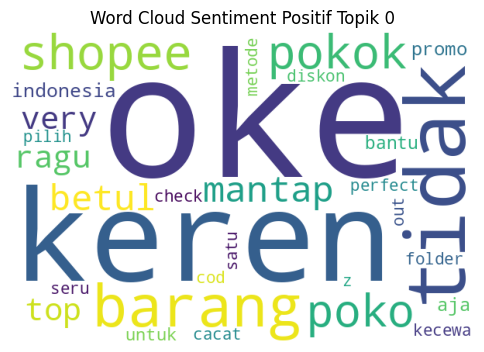

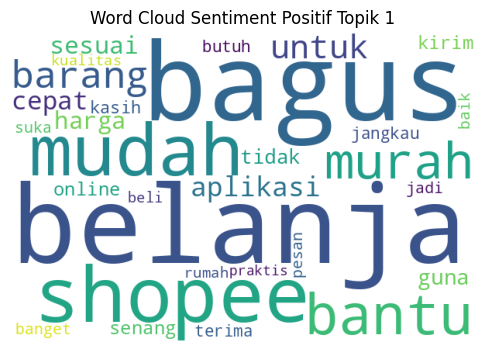

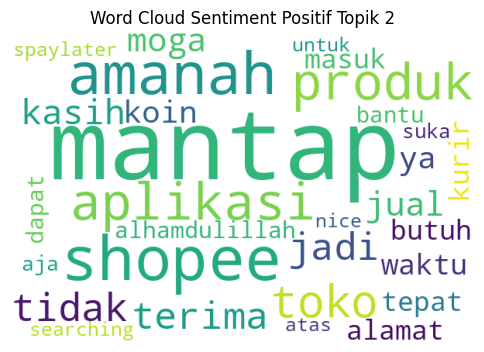

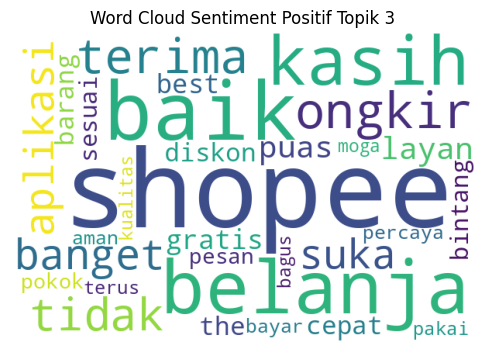

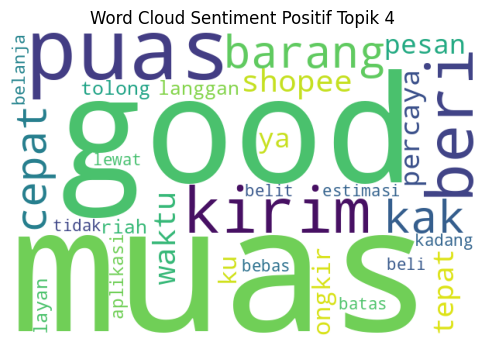

In [ ]:
for t in range(lda_pos_NB.num_topics):
    plt.figure(figsize=(6,6))
    plt.title(f"Word Cloud Sentiment Positif Topik {t}")

    words = dict(lda_pos_NB.show_topic(t, 30))

    wc_NB = WordCloud(background_color='white', width=600, height=400)
    plt.imshow(wc_NB.generate_from_frequencies(words))
    plt.axis("off")

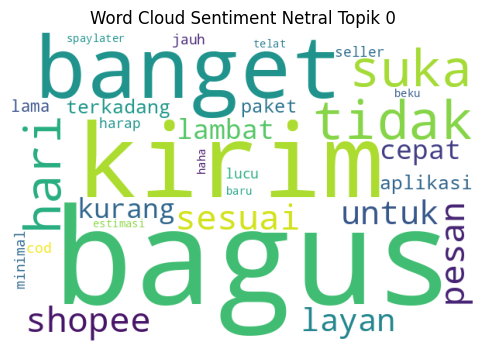

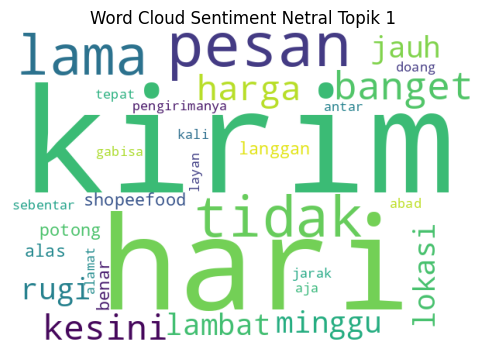

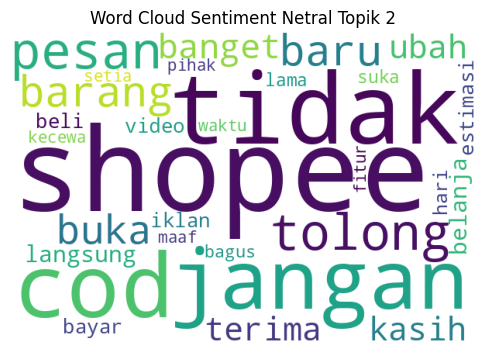

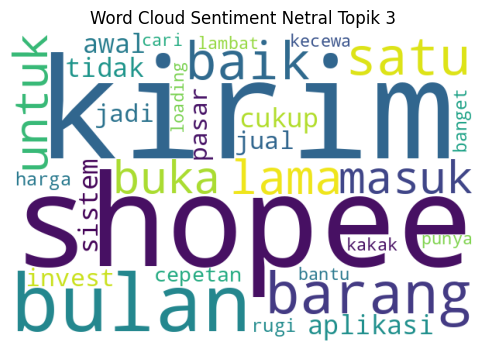

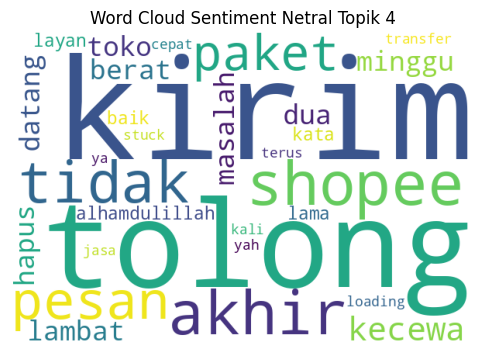

In [ ]:
for t in range(lda_neu_NB.num_topics):
    plt.figure(figsize=(6,6))
    plt.title(f"Word Cloud Sentiment Netral Topik {t}")

    words = dict(lda_neu_NB.show_topic(t, 30))

    wc_NB = WordCloud(background_color='white', width=600, height=400)
    plt.imshow(wc_NB.generate_from_frequencies(words))
    plt.axis("off")

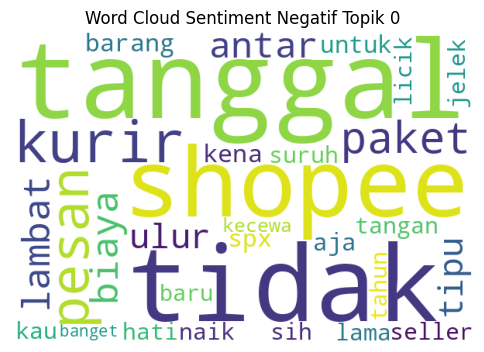

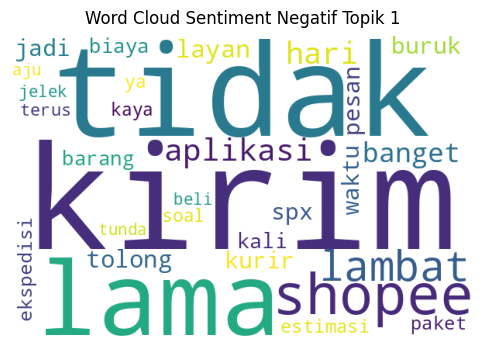

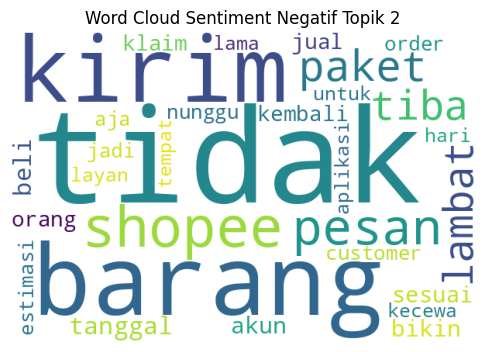

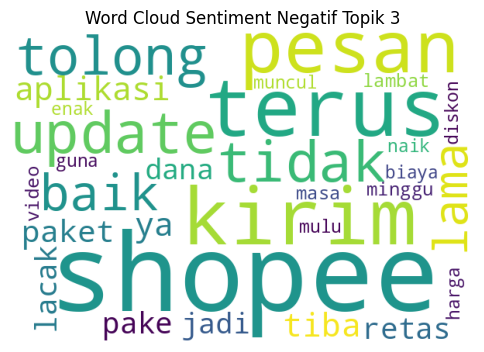

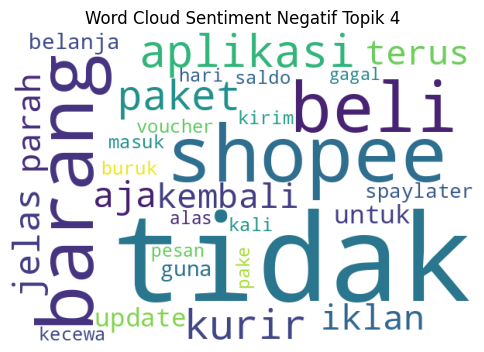

In [ ]:
for t in range(lda_neg_NB.num_topics):
    plt.figure(figsize=(6,6))
    plt.title(f"Word Cloud Sentiment Negatif Topik {t}")

    words = dict(lda_neg_NB.show_topic(t, 30))

    wc_NB = WordCloud(background_color='white', width=600, height=400)
    plt.imshow(wc_NB.generate_from_frequencies(words))
    plt.axis("off")

## **Bar Chart**

In [ ]:
import seaborn as sns
import pandas as pd

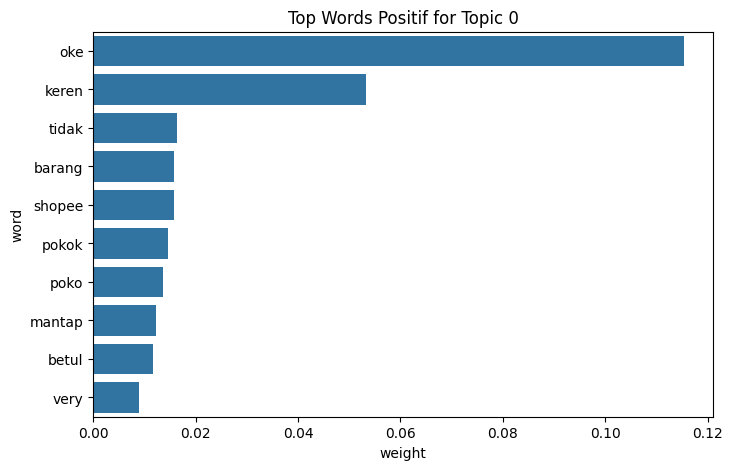

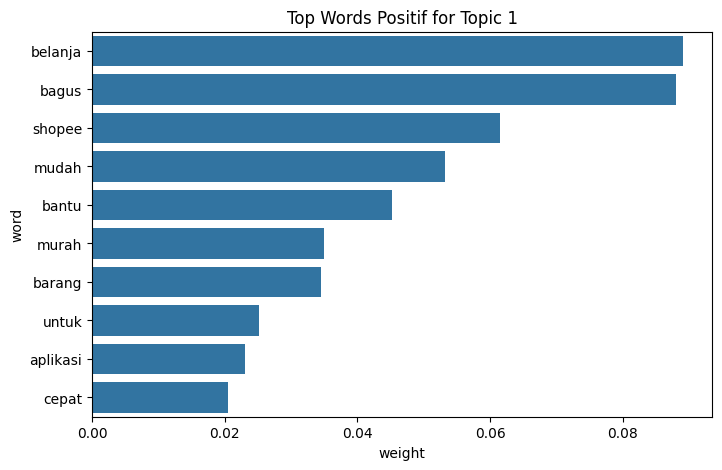

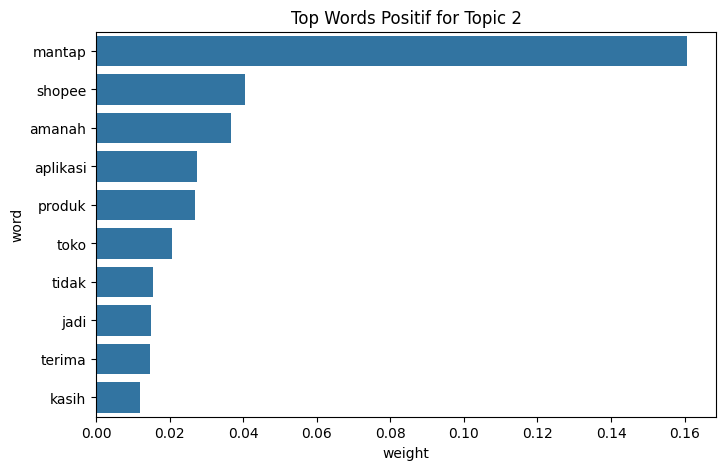

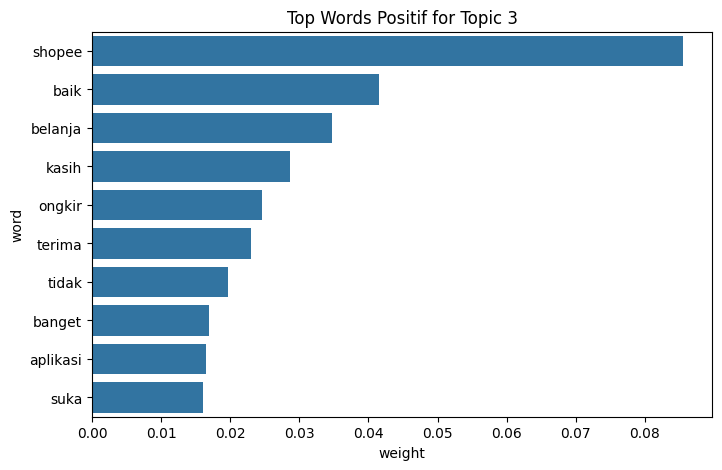

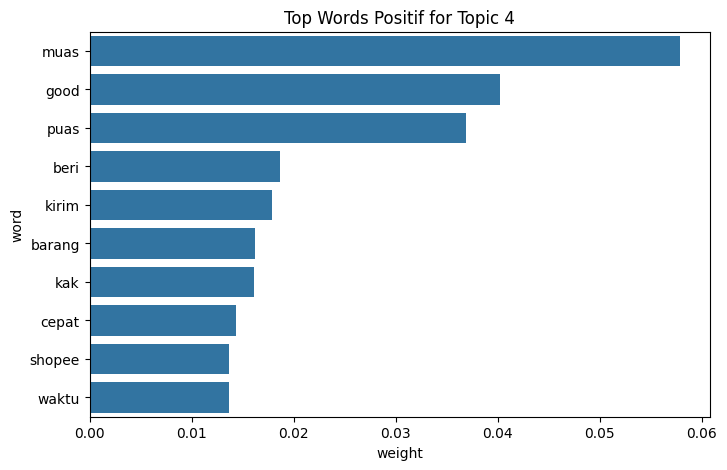

In [ ]:
for t in range(lda_pos_NB.num_topics):
    df_topic = pd.DataFrame(lda_pos_NB.show_topic(t, 10), columns=['word', 'weight'])

    plt.figure(figsize=(8,5))
    sns.barplot(x='weight', y='word', data=df_topic)
    plt.title(f"Top Words Positif for Topic {t}")
    plt.show()

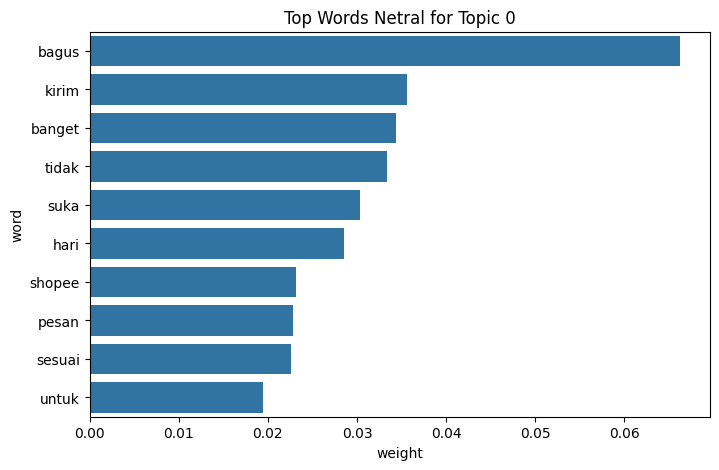

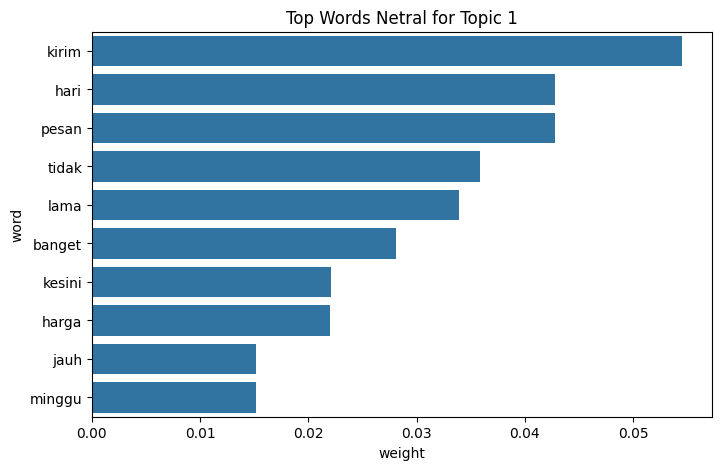

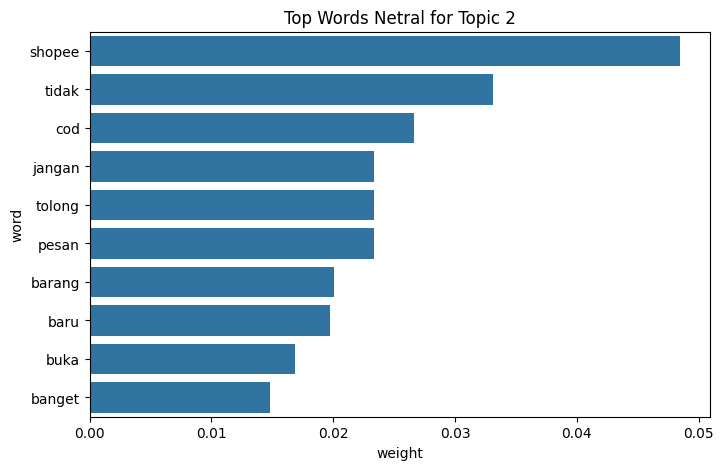

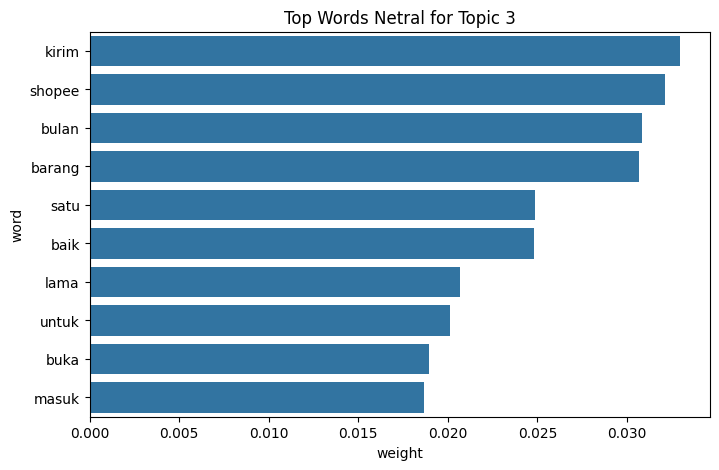

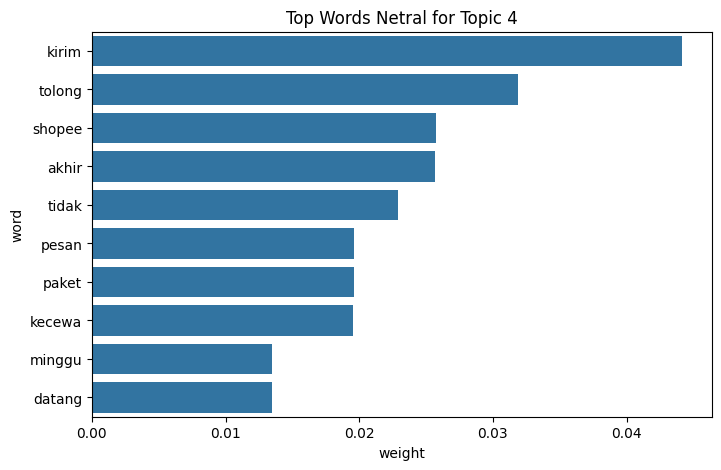

In [ ]:
for t in range(lda_neu_NB.num_topics):
    df_topic = pd.DataFrame(lda_neu_NB.show_topic(t, 10), columns=['word', 'weight'])

    plt.figure(figsize=(8,5))
    sns.barplot(x='weight', y='word', data=df_topic)
    plt.title(f"Top Words Netral for Topic {t}")
    plt.show()

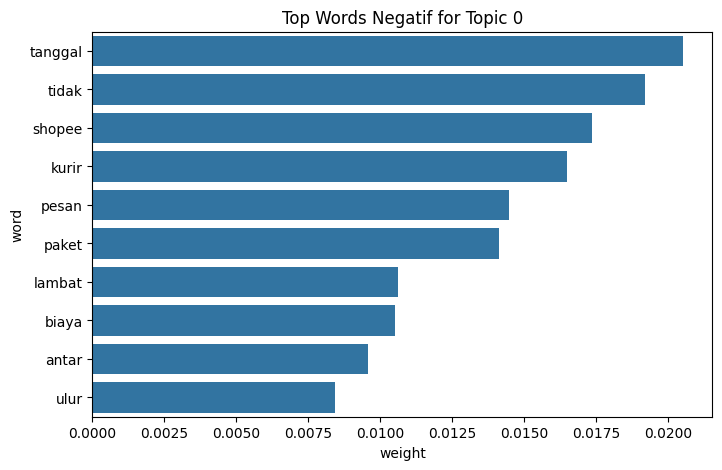

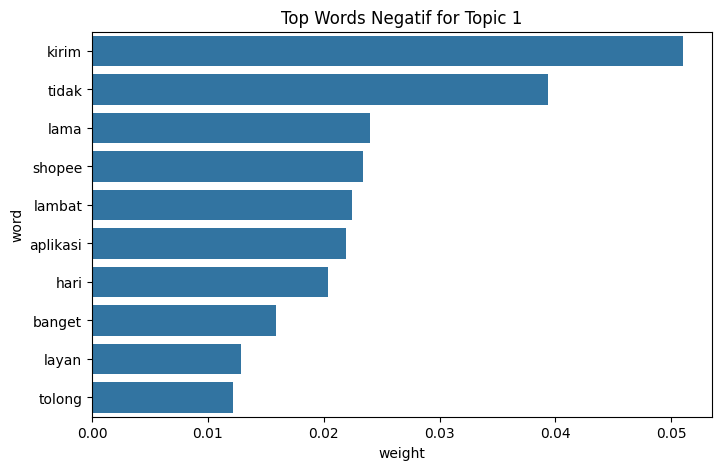

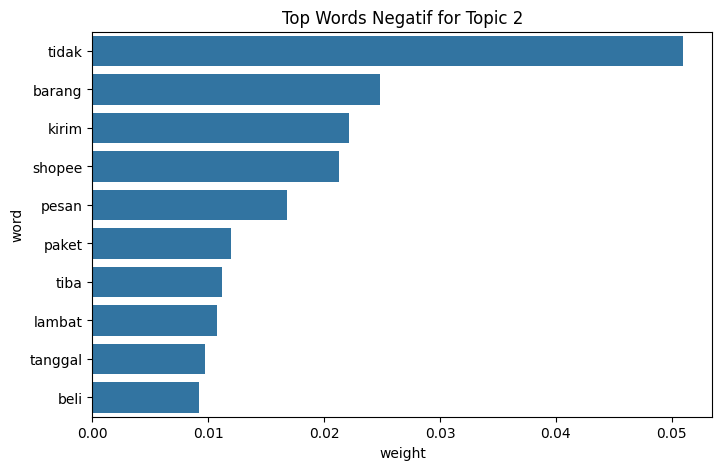

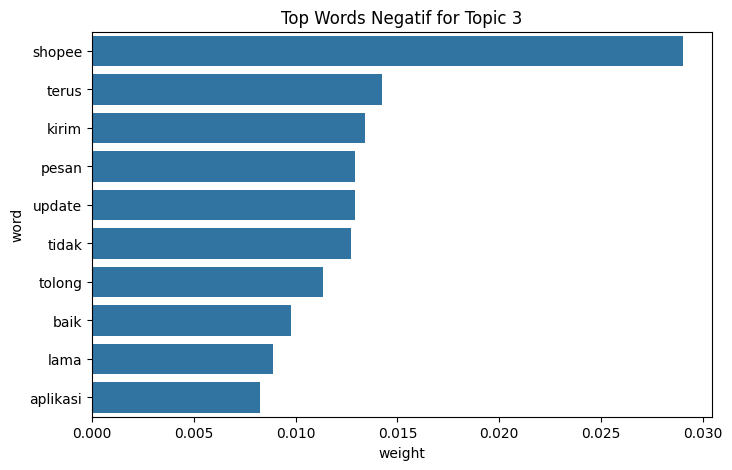

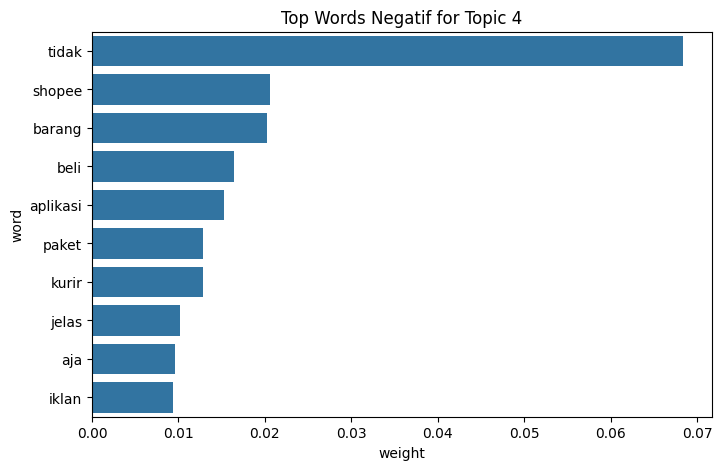

In [ ]:
for t in range(lda_neg_NB.num_topics):
    df_topic = pd.DataFrame(lda_neg_NB.show_topic(t, 10), columns=['word', 'weight'])

    plt.figure(figsize=(8,5))
    sns.barplot(x='weight', y='word', data=df_topic)
    plt.title(f"Top Words Negatif for Topic {t}")
    plt.show()

## **Heatmap**

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
def lda_heatmap(lda_model, dictionary, label_sentimen, top_n=10):
    topics_data = []

    for topic_id in range(lda_model.num_topics):
        terms = lda_model.show_topic(topic_id, top_n)

        for word, weight in terms:
            topics_data.append({
                "Topik": f"Topik {topic_id}",
                "Kata": word,
                "Bobot": weight
            })

    df_topics = pd.DataFrame(topics_data)

    heatmap_data = df_topics.pivot_table(
        index="Kata",
        columns="Topik",
        values="Bobot",
        fill_value=0
    )

    plt.figure(figsize=(10, 8))
    sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd")
    plt.title(f"Heatmap Topik × Kata ({label_sentimen})")
    plt.xlabel("Topik")
    plt.ylabel("Kata")
    plt.show()

    return heatmap_data

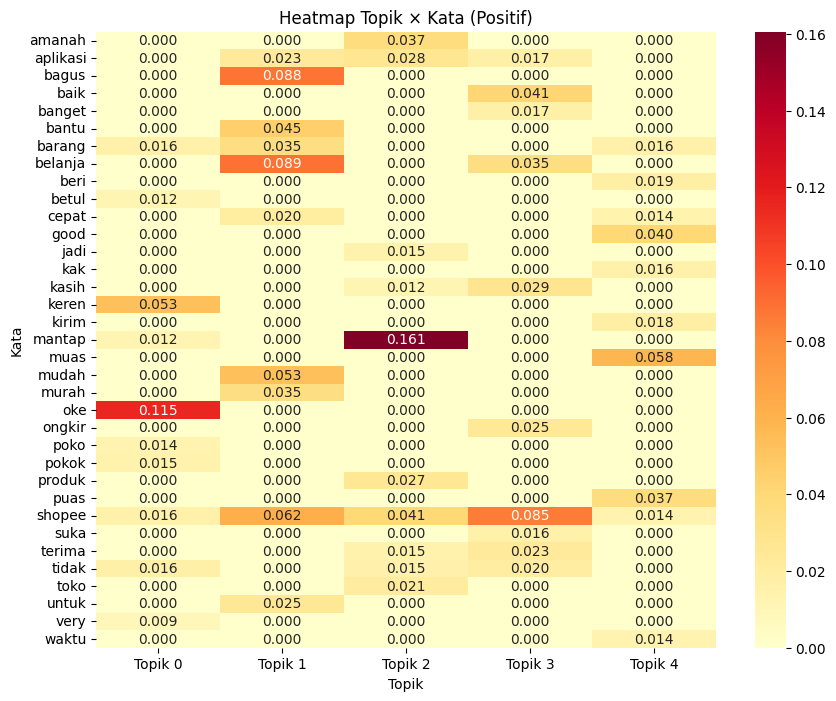

In [ ]:
heatmap_pos_NB = lda_heatmap(lda_pos_NB, dictionary_pos_NB, "Positif")

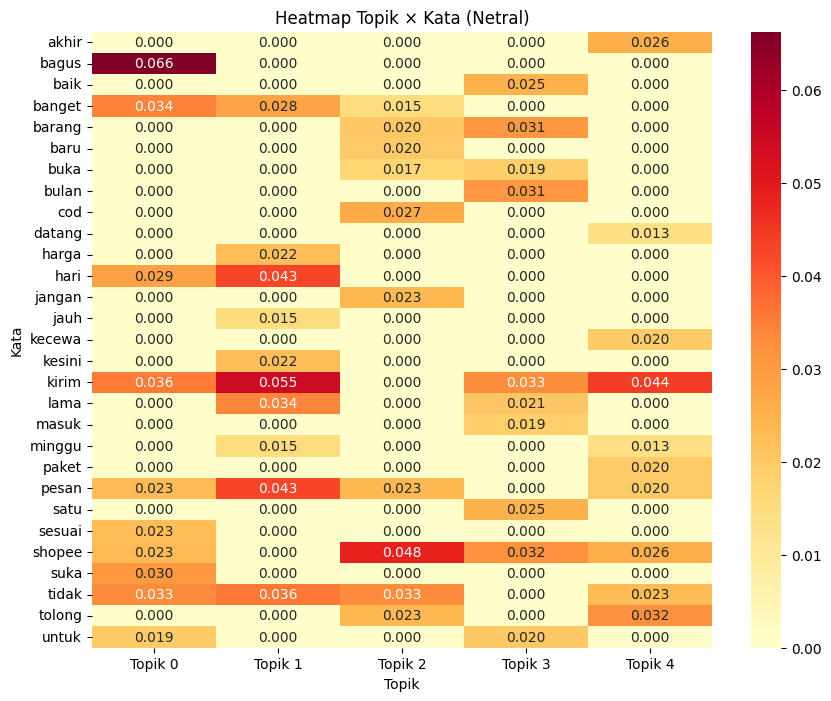

In [ ]:
heatmap_neu_NB = lda_heatmap(lda_neu_NB, dictionary_neu_NB, "Netral")

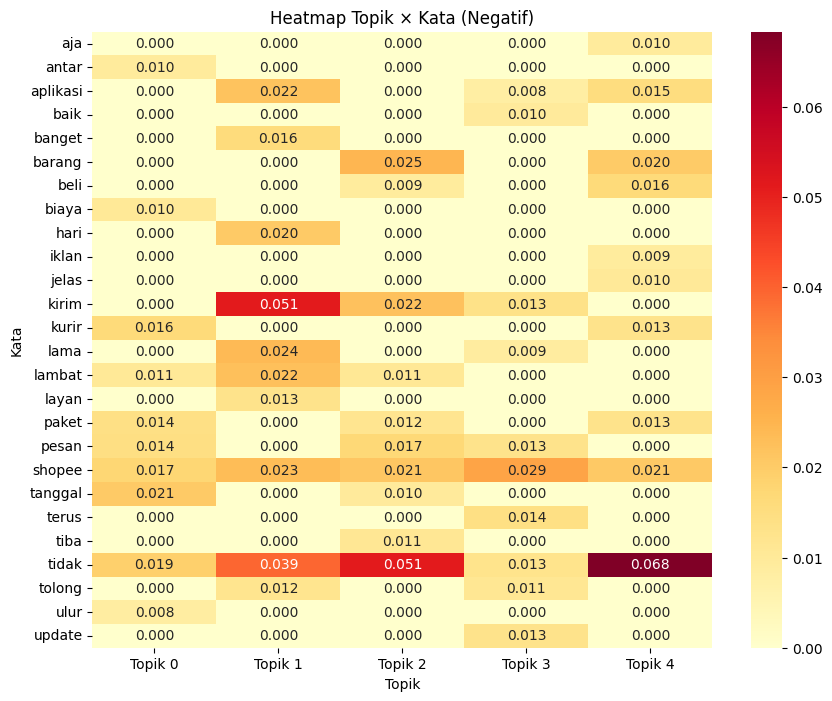

In [ ]:
heatmap_neg_NB = lda_heatmap(lda_neg_NB, dictionary_neg_NB, "Negatif")

## **pyLDAvis**

In [ ]:
!pip install pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 33.1 MB/s eta 0:00:00


In [ ]:
import pyLDAvis
import pyLDAvis.gensim
pyLDAvis.enable_notebook()

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
def show_pyLDAvis(lda_model, corpus, dictionary, label_sentimen):
    print(f" Visualisasi pyLDAvis untuk sentimen: {label_sentimen}")

    vis = pyLDAvis.gensim.prepare(
        lda_model,
        corpus,
        dictionary,
        sort_topics=False
    )
    return vis

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
vis_pos_NB = show_pyLDAvis(lda_pos_NB, corpus_pos_NB, dictionary_pos_NB, "Positif")
pyLDAvis.display(vis_pos_NB)

 Visualisasi pyLDAvis untuk sentimen: Positif


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
vis_neu_NB = show_pyLDAvis(lda_neu_NB, corpus_neu_NB, dictionary_neu_NB, "Netral")
pyLDAvis.display(vis_neu_NB)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

 Visualisasi pyLDAvis untuk sentimen: Netral


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
vis_neg_NB = show_pyLDAvis(lda_neg_NB, corpus_neg_NB, dictionary_neg_NB, "Negatif")
pyLDAvis.display(vis_neg_NB)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

 Visualisasi pyLDAvis untuk sentimen: Negatif


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag